In [15]:
# Libraries:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

scikit-learn modules:

In [2]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [5]:
housing = fetch_california_housing()

In [6]:
print(housing.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [8]:
print("Data shape:", housing.data.shape)
print("Target shape:", housing.target.shape)

Data shape: (20640, 8)
Target shape: (20640,)


In [9]:
print("Feature names:", housing.feature_names)

Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [11]:
pd.set_option('display.precision', 2)   # output to 2 d.p
pd.set_option('display.max_columns', 9) # Show 9 columns
pd.set_option('display.width', None)

# Create a pandas DataFrame from the dataset
df = pd.DataFrame(housing.data, columns=housing.feature_names)

# Add the target column
df['MedHouseVal'] = housing.target


In [12]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.33,41.0,6.98,1.02,322.0,2.56,37.88,-122.23,4.53
1,8.30,21.0,6.24,0.97,2401.0,2.11,37.86,-122.22,3.58
2,7.26,52.0,8.29,1.07,496.0,2.80,37.85,-122.24,3.52
3,5.64,52.0,5.82,1.07,558.0,2.55,37.85,-122.25,3.41
4,3.85,52.0,6.28,1.08,565.0,2.18,37.85,-122.25,3.42


In [13]:
# Take a random 10% sample of the dataset
sample_df = df.sample(frac=0.1, random_state=17)

# Print the sample size
print("Sample size:", sample_df.shape)


Sample size: (2064, 9)


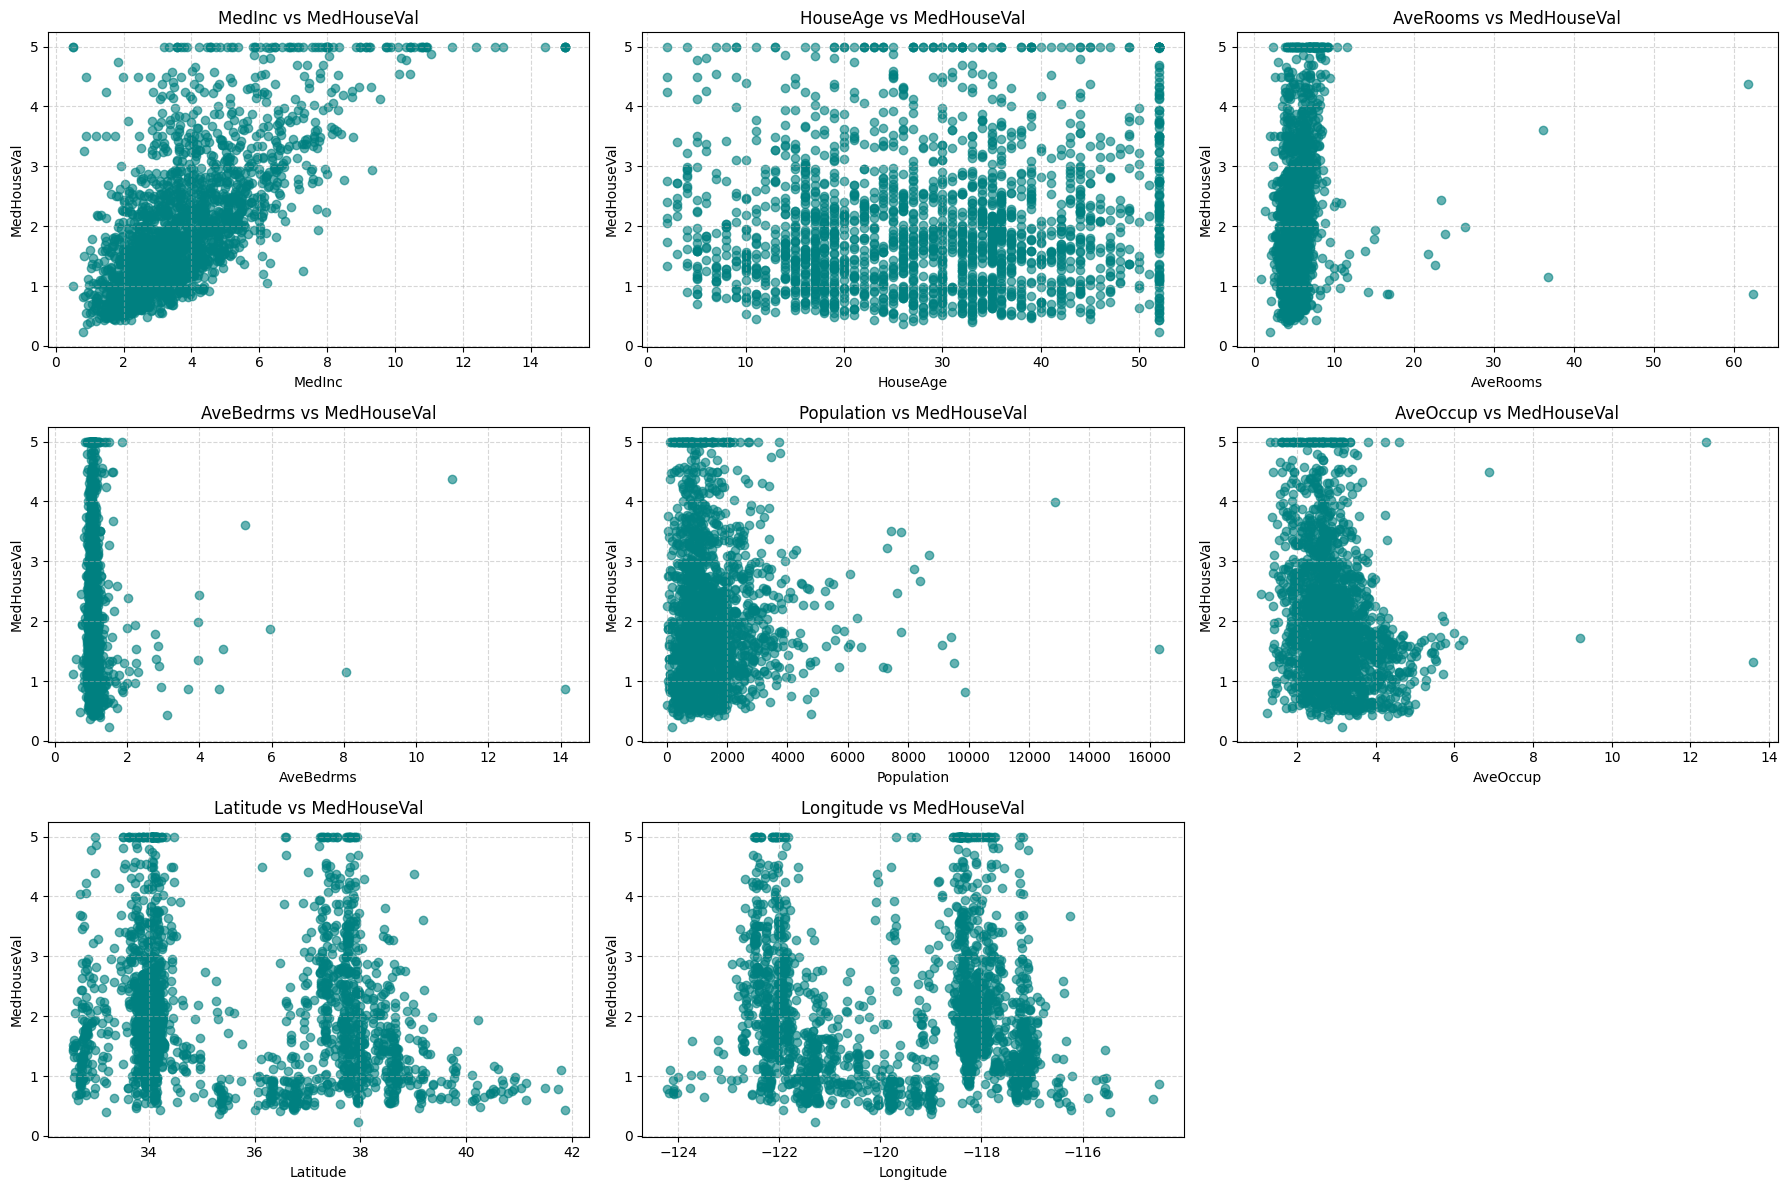

In [16]:
features = housing.feature_names
target = 'MedHouseVal'
cols = 3
rows = math.ceil(len(features)/cols)

plt.figure(figsize=(6*cols, 4*rows))

for i, f in enumerate(features, 1):
    plt.subplot(rows, cols, i)
    plt.scatter(sample_df[f], sample_df[target], alpha=0.6, color='teal')
    plt.xlabel(f)
    plt.ylabel(target)
    plt.title(f"{f} vs {target}")
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [20]:
X = housing.data       # Features
y = housing.target     # Target

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [22]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [24]:
y_pred = model.predict(X_test)

In [25]:
# Evaluate model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Print metrics neatly
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.2f}")

Mean Absolute Error (MAE): 0.53
Mean Squared Error (MSE): 0.56
Root Mean Squared Error (RMSE): 0.75
R² Score: 0.58


In [26]:
coef_df = pd.DataFrame({
    "Feature": housing.feature_names,   # Feature names
    "Coefficient": model.coef_          # Corresponding coefficients learned by the model
}).sort_values(by="Coefficient", ascending=False)  # Sort by coefficient

coef_df  # Display the DataFrame

,Feature,Coefficient
3,AveBedrms,7.83e-01
0,MedInc,4.49e-01
1,HouseAge,9.72e-03
4,Population,-2.03e-06
5,AveOccup,-3.53e-03
2,AveRooms,-1.23e-01
6,Latitude,-4.20e-01
7,Longitude,-4.34e-01


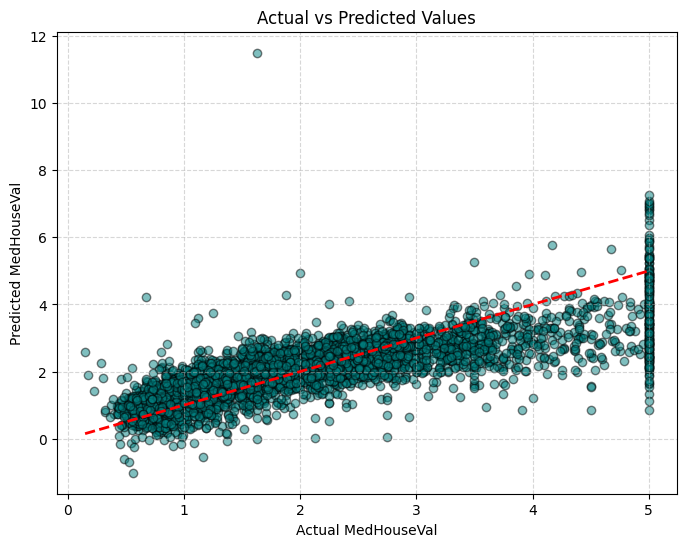

In [32]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='teal', edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)  # perfect fit line
plt.xlabel("Actual MedHouseVal")
plt.ylabel("Predicted MedHouseVal")
plt.title("Actual vs Predicted Values")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()